<a href="https://colab.research.google.com/github/alanJoshiGeorge/ai-ml-lab/blob/main/ann.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:

import numpy as np
def sigmoid(x):
    return 1 / (1 + np.exp(-np.clip(x, -500, 500)))

def sigmoid_derivative(output):
    return output * (1 - output)

X = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
], dtype=float)

y = np.array([
    [0],
    [1],
    [1],
    [0]
], dtype=float)

np.random.seed(42)

input_neurons = 2
hidden_neurons = 3
output_neurons = 1

W1 = np.random.randn(input_neurons, hidden_neurons) * 0.5
b1 = np.zeros((1, hidden_neurons))

W2 = np.random.randn(hidden_neurons, output_neurons) * 0.5
b2 = np.zeros((1, output_neurons))

learning_rate = 1.0
epochs = 2000

for epoch in range(epochs):

    # FORWARD PROPAGATION
    z1 = X @ W1 + b1
    a1 = sigmoid(z1)

    z2 = a1 @ W2 + b2
    a2 = sigmoid(z2)

    # Calculate prediction error
    error = a2 - y
    loss = 0.5 * np.mean(error ** 2)

    # BACKPROPAGATION
    # Output layer gradient
    delta2 = error * sigmoid_derivative(a2)
    delta2 /= len(X)

    dW2 = a1.T @ delta2
    db2 = np.sum(delta2, axis=0, keepdims=True)

    # Hidden layer gradient
    delta1 = (delta2 @ W2.T) * sigmoid_derivative(a1)

    dW1 = X.T @ delta1
    db1 = np.sum(delta1, axis=0, keepdims=True)

    # UPDATE WEIGHTS AND BIASES
    W2 -= learning_rate * dW2
    b2 -= learning_rate * db2

    W1 -= learning_rate * dW1
    b1 -= learning_rate * db1

    if epoch % 2000 == 0:
        print(f"Epoch {epoch}, Loss: {loss:.6f}")


# -------------------------------
# 5. Test the trained network
# -------------------------------
print("\nPredictions after training:")

hidden = sigmoid(X @ W1 + b1)
predictions = sigmoid(hidden @ W2 + b2)

for inputs, prediction, target in zip(X, predictions, y):
    print(
        f"Input: {inputs.astype(int)} | "
        f"Prediction: {prediction[0]:.4f} | "
        f"Target: {int(target[0])}"
    )

Epoch 0, Loss: 0.133791

Predictions after training:
Input: [0 0] | Prediction: 0.1285 | Target: 0
Input: [0 1] | Prediction: 0.8644 | Target: 1
Input: [1 0] | Prediction: 0.8654 | Target: 1
Input: [1 1] | Prediction: 0.1563 | Target: 0


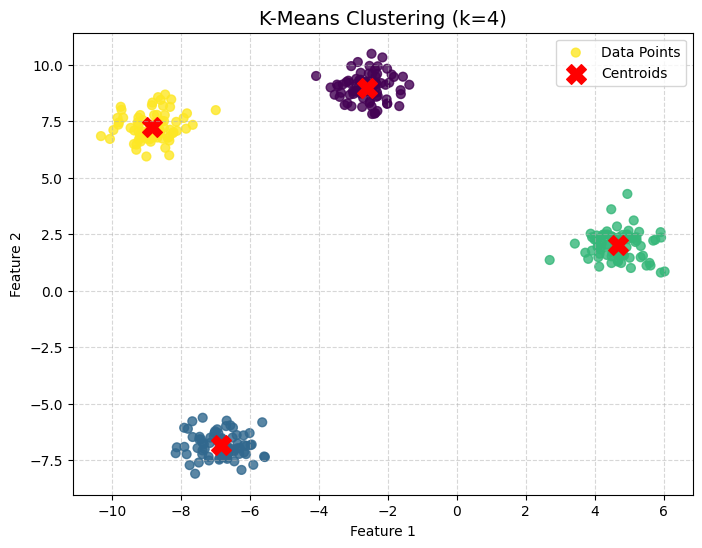

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs

# 1. Generate synthetic 2D data
X, y_true = make_blobs(n_samples=300, centers=4, cluster_std=0.60, random_state=42)

# 2. Initialize and fit the KMeans model
k = 4
kmeans = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42)
y_kmeans = kmeans.fit_predict(X)

# Extract cluster centroids
centroids = kmeans.cluster_centers_

# 3. Plot the results
plt.figure(figsize=(8, 6))

# Plot the data points colored by cluster assignment
plt.scatter(X[:, 0], X[:, 1], c=y_kmeans, s=40, cmap='viridis', alpha=0.8, label='Data Points')

# Plot the cluster centers (centroids)
plt.scatter(centroids[:, 0], centroids[:, 1], c='red', s=200, marker='X', label='Centroids')

plt.title(f'K-Means Clustering (k={k})', fontsize=14)
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()